# Island Arrivals | Forecasting monthly tourist arrivals in Sri Lanka

How accurately can we forecast next month's arrivals using the counts available at the end of this month? Each experiment uses the same 36 test months from January 2023 to December 2025.

- **Experiment 1 — Bagging and boosting.** Compare Random Forest and XGBoost with a forecast that repeats last year's count for the same month.
- **Experiment 2 — Stacking (Random Forest + XGBoost).** Test whether a linear regression can improve on the two forecasts by learning how to combine them.
- **Experiment 3 — ARIMA + Random Forest.** Test whether a forest can predict the error left by a one-month autoregressive forecast.

### Project links

- [Open the interactive dashboard](https://island-arrivals-wrohjslu8dycwbowskv6xg.streamlit.app/) to compare forecasts and explore how a different December count changes the January estimate.
- [View the project on GitHub](https://github.com/indunil-bandara/island-arrivals/blob/main/cloud/streamlit_app.py) to see the Python entry point for the Streamlit dashboard.

Run the notebook from the project folder so it can load the dataset and shared training code.

## 1. Data provenance and quality
National monthly arrivals from the Sri Lanka Tourism Development Authority. The CSV records the bulletin URL beside each observation. April–November 2020 are dashes in the source. The other four months add to the published annual total of 507,704, so we encode those eight months as zero and retain the note for audit.

Data source: [SLTDA monthly tourist arrivals reports](https://www.sltda.gov.lk/en/monthly-tourist-arrivals-reports).

Monthly records: 132  | Annual 2020 total: 507704
note
dash reconciled to annual total      8
reported                           124


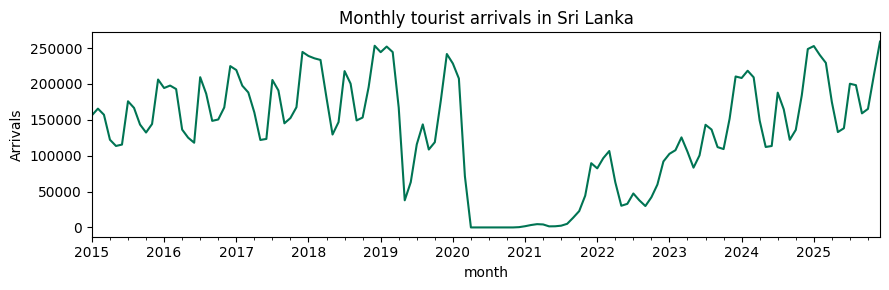

In [1]:
from pathlib import Path
import pickle
import pandas as pd
import matplotlib.pyplot as plt
from train import dataset, train, FEATURES
from model import NAMES, predict_one, features
raw=pd.read_csv("data/arrivals.csv",parse_dates=["month"])
assert raw.month.is_unique and raw.arrivals.notna().all()
print("Monthly records:",len(raw)," | Annual 2020 total:",raw.loc[raw.month.dt.year==2020,"arrivals"].sum())
print(raw.groupby("note").size().to_string())
raw.plot(x="month",y="arrivals",figsize=(9,3),legend=False,color="#007453",title="Monthly tourist arrivals in Sri Lanka",ylabel="Arrivals")
plt.tight_layout()
plt.show()

## 2. Features and chronological folds
The target is the current month’s count. Lag 1, lag 2 and lag 12 use earlier observations. Sine and cosine encode the forecast month’s known calendar position. The first 12 months supply lag history. We use an expanding training window and freeze model parameters throughout each test year. Previous test months become observed lag inputs when their months have ended.

In [2]:
frame=dataset()
print(frame[["month","arrivals"]+FEATURES].head(3).to_string(index=False))
for year in (2023,2024,2025):
    h=frame[frame.month.dt.year<year]
    print(year,"| training rows:",len(h),"| final training month:",h.month.max().strftime("%Y-%m"),"| test months: 12")

     month  arrivals     lag1     lag2    lag12  season_sin   season_cos
2016-01-01    194280 206114.0 144147.0 156246.0    0.500000 8.660254e-01
2016-02-01    197697 194280.0 206114.0 165541.0    0.866025 5.000000e-01
2016-03-01    192841 197697.0 194280.0 157051.0    1.000000 6.123234e-17
2023 | training rows: 84 | final training month: 2022-12 | test months: 12
2024 | training rows: 96 | final training month: 2023-12 | test months: 12
2025 | training rows: 108 | final training month: 2024-12 | test months: 12


## 3. Fit, compare and export
Seasonal naive repeats lag 12. The dashboard label ARIMA refers to ARIMA(1,0,0), also called AR(1). It fits an intercept and slope to the previous month’s arrivals by least squares. Random Forest and XGBoost use all five inputs. ARIMA + Random Forest adds a forest estimate of the ARIMA training residual to the linear forecast. Stacking uses the RF and XGBoost forecasts as two inputs to a linear regression. Four expanding-window splits inside each training period generate out-of-fold forecasts. The meta-model fits only those forecasts and their observed targets. Both base learners are then refitted on the full training period for inference. Fixed settings are reused across folds. All outputs have a lower bound of zero. The comparison below uses the same windows and inputs available at each forecast date.

In [3]:
import inspect
from train import forest, fit, fit_base, fit_stacker
print(inspect.getsource(fit_stacker))
print(inspect.getsource(fit_base))
print(inspect.getsource(forest))
print(inspect.getsource(fit))
report=train()
print("Saved fitted parameters and chronological holdout predictions.")

def fit_stacker(x, y):
    # Every row seen by the meta-model was forecast by earlier-only base models.
    meta_inputs, targets = [], []
    for earlier, later in TimeSeriesSplit(n_splits=4).split(x):
        rf, boost = fit_base(x[earlier], y[earlier])
        meta_inputs.append(np.column_stack([rf.predict(x[later]), boost.predict(x[later])]))
        targets.extend(y[later])
    return LinearRegression().fit(np.vstack(meta_inputs), targets)

def fit_base(x, y):
    rf = forest().fit(x, y)
    boost = XGBRegressor(n_estimators=60, max_depth=2, learning_rate=.075, objective="reg:squarederror", n_jobs=1, random_state=42).fit(x, y)
    return rf, boost

def forest():
    return RandomForestRegressor(n_estimators=48, max_depth=5, min_samples_leaf=2, random_state=42, n_jobs=1)

def fit(frame):
    x, y = frame[FEATURES].to_numpy(), frame.arrivals.to_numpy()
    stacker = fit_stacker(x, y)
    rf, boost = fit_base(x, y)
    slope, intercept = np.polyfit(x[:, 0], y, 1)
    residuals = y - (

## Experiment 1 — Bagging (Random Forest) and boosting (XGBoost)
Which tree ensemble forecasts monthly arrivals more accurately? Both use the same five features and 36 test months. The seasonal naive baseline repeats the count from the same month one year earlier.

                  MAE   RMSE
Seasonal naive  45626  55563
Random Forest   23865  30990
XGBoost         25008  31728


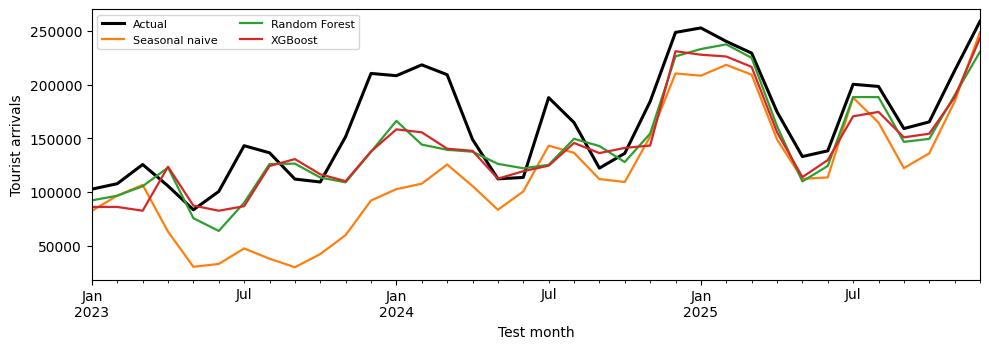

In [4]:
display_names = {"AR(1)": "ARIMA", "AR + Forest": "ARIMA + Random Forest"}
months = pd.to_datetime([row["month"] for row in report["rows"]])
forecasts = pd.DataFrame([row["pred"] for row in report["rows"]], index=months)
forecasts = forecasts.rename(columns=display_names)
forecasts["Actual"] = [row["actual"] for row in report["rows"]]
scores = pd.DataFrame(report["scores"]["All years"]).T.rename(index=display_names)

def compare(models):
    print(scores.loc[models, ["MAE", "RMSE"]].round().astype(int).to_string())
    ax = forecasts[["Actual", *models]].plot(figsize=(10, 3.6), linewidth=1.6)
    ax.lines[0].set(color="black", linewidth=2.2)
    ax.set(xlabel="Test month", ylabel="Tourist arrivals")
    ax.legend(ncol=2, fontsize=8)
    plt.tight_layout()
    plt.show()

compare(["Seasonal naive", "Random Forest", "XGBoost"])

### Interpretation of Results

Across the 36 test months, Random Forest missed the observed count by 23,865 arrivals per month on average. XGBoost missed by 25,008 and the seasonal baseline by 45,626. The gap between the two tree models was small compared with the improvement each made over the baseline.

The annual scores show why the test period matters. In 2024, XGBoost had the lower MAE (29,882 versus 31,585). Random Forest had the lower MAE in 2023 and 2025 and the lower RMSE across all three years combined (30,990 versus 31,728).

## Experiment 2 — Stacking (Random Forest + XGBoost, with linear regression)
Can a linear regression combine the RF and XGBoost predictions more accurately than either model alone? The regression learns its weights from four chronological splits inside each training period.

                 MAE   RMSE
Random Forest  23865  30990
XGBoost        25008  31728
Stacking       47677  54800


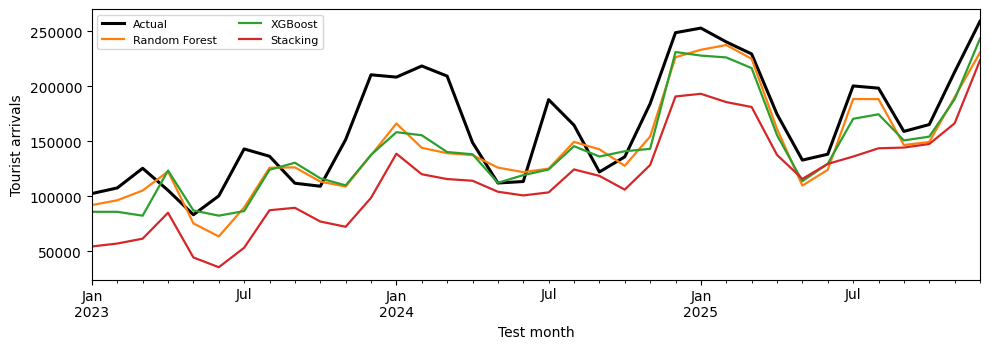

In [6]:
compare(["Random Forest", "XGBoost", "Stacking"])

### Interpretation of Results

The linear regression combined the Random Forest and XGBoost forecasts using weights learned from earlier months. On the 36 held-out months its MAE was 47,677 arrivals, compared with 23,865 for Random Forest and 25,008 for XGBoost. Its MAE exceeded both base models in each of the three test years.

RMSE gives more weight to large misses. It also ranked stacking last among these three models (54,800). For this tourism series and these training windows, using the learned combination would therefore have increased forecast error under either measure.

## Experiment 3 — ARIMA + Random Forest
Does a forest improve the ARIMA forecast by predicting its error? The training target for the correction is actual arrivals minus the fitted ARIMA value. At prediction time, the forest uses lagged arrivals and calendar features to estimate the correction.

                         MAE   RMSE
ARIMA                  26696  34593
Random Forest          23865  30990
ARIMA + Random Forest  16710  22816


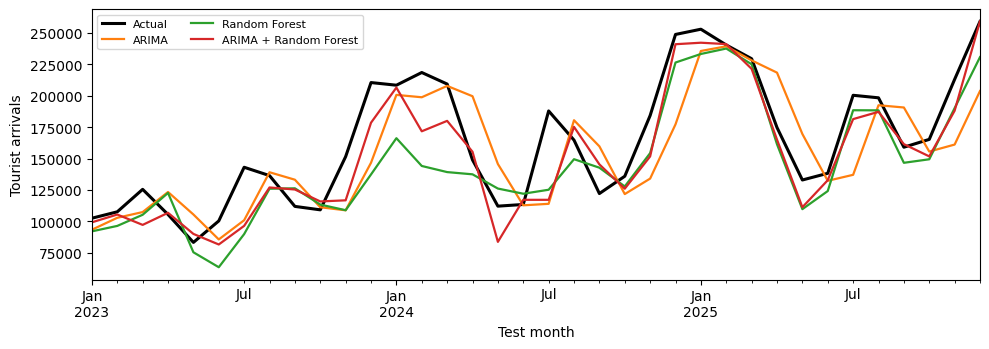

In [5]:
compare(["ARIMA", "Random Forest", "ARIMA + Random Forest"])

### Interpretation of Results

Adding the forest correction reduced pooled MAE from 26,696 arrivals for ARIMA alone to 16,710 for the hybrid. That amounts to about 9,986 fewer arrivals of absolute error per month on average, a 37.4% reduction. Pooled RMSE also fell, from 34,593 to 22,816.

The improvement was visible in every test year and was largest in 2025, when MAE fell from 26,941 to 10,612. The hybrid also beat Random Forest alone in all three years. Among the six methods tested, this gives the strongest historical support for using the hybrid in the dashboard's January scenario.

## Results across test years
Each column uses the same months for all six methods. MAE and RMSE are measured in tourist arrivals.

MAE (arrivals)
                        2023   2024   2025  All years
Seasonal naive         63944  47180  25755      45626
ARIMA                  21767  31381  26941      26696
Random Forest          25114  31585  14896      23865
XGBoost                27481  29882  17662      25008
ARIMA + Random Forest  16937  22580  10612      16710
Stacking               55844  48987  38200      47677
RMSE (arrivals)
                        2023   2024   2025  All years
Seasonal naive         72267  57346  27394      55563
ARIMA                  28249  39855  34693      34593
Random Forest          32472  39393  16581      30990
XGBoost                34148  38681  18913      31728
ARIMA + Random Forest  22209  29941  13116      22816
Stacking               61743  58248  42476      54800
Hybrid reduction against ARIMA, percent:
2023         22.2
2024         28.0
2025         60.6
All years    37.4
dtype: float64


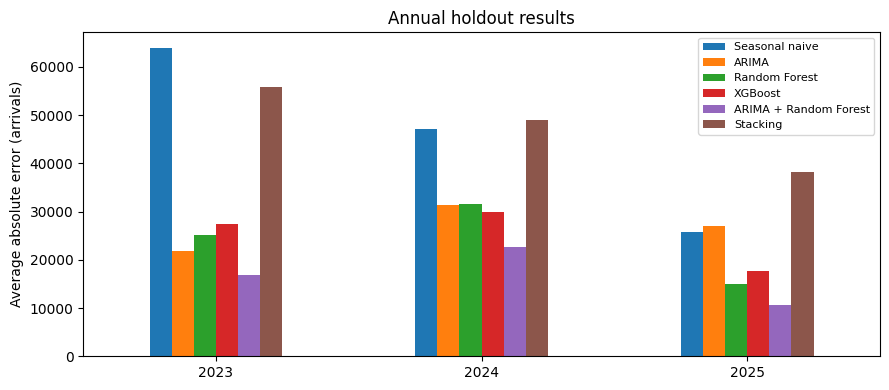

In [7]:
mae=pd.DataFrame({k:{n:s["MAE"] for n,s in v.items()} for k,v in report["scores"].items()})
rmse=pd.DataFrame({k:{n:s["RMSE"] for n,s in v.items()} for k,v in report["scores"].items()})
display_names = {"AR(1)": "ARIMA", "AR + Forest": "ARIMA + Random Forest"}
mae = mae.rename(index=display_names)
rmse = rmse.rename(index=display_names)
print("MAE (arrivals)"); print(mae.round().astype(int))
print("RMSE (arrivals)"); print(rmse.round().astype(int))
print("Hybrid reduction against ARIMA, percent:"); print(((1-mae.loc["ARIMA + Random Forest"]/mae.loc["ARIMA"])*100).round(1))
mae.iloc[:,:3].T.plot(kind="bar",figsize=(9,4),rot=0,ylabel="Average absolute error (arrivals)",title="Annual holdout results")
plt.legend(fontsize=8); plt.tight_layout(); plt.show()

## January scenario and limitations
Pooled MAE averages absolute errors over all 36 observations. Pooled RMSE takes the square root after averaging squared errors across all 36 observations. Stacking had pooled MAE of 47,677, higher than either base model. Combining predictions did not improve this test. The ARIMA + Random Forest hybrid won all three years by MAE. Random Forest and XGBoost exchanged rank in 2024. Thirty-six months and three adjacent annual windows cannot establish performance under future disruptions. Post-evaluation model fitting uses all 120 eligible rows for the January 2026 historical replay.

In [8]:
with open("models/arrivals.pkl","rb") as file:
    fitted=pickle.load(file)
for december in [report["prior"],200000]:
    row=features(1,december,report["two_back"],report["year_back"])
    print("December assumption:",december,"| January estimates:",{display_names.get(k, k):round(v) for k,v in predict_one(fitted,row).items()})

December assumption: 258928 | January estimates: {'Seasonal naive': 252761, 'ARIMA': 245811, 'Random Forest': 238626, 'XGBoost': 220550, 'ARIMA + Random Forest': 235070, 'Stacking': 191955}
December assumption: 200000 | January estimates: {'Seasonal naive': 252761, 'ARIMA': 193114, 'Random Forest': 217607, 'XGBoost': 196812, 'ARIMA + Random Forest': 175663, 'Stacking': 165706}


## Research comparison

| Method | Strength for tabular regression | Limitation in this study | Status |
|---|---|---|---|
| Random Forest | Bootstrap-tree averages can model lag interactions with little preprocessing. | Leaf predictions average training targets, limiting extrapolation during a recovery. | Evaluated |
| XGBoost | Sequential regularized trees correct residual errors. | Depth, shrinkage and boosting rounds influence bias and variance in a short series. | Evaluated |
| LightGBM | Histogram-based, leaf-wise growth is designed for efficient large-scale boosting. | Extra speed offers little advantage for 120 rows; depth and leaf size require care. | Literature comparison |
| CatBoost | Ordered boosting and category handling suit mixed numerical and categorical columns. | These five inputs are numeric, limiting the relevance of categorical processing. | Literature comparison |

**Tabular, image and text inputs.** Each tourism row already supplies a fixed numerical vector. With images, a forest on flattened pixels has to learn local spatial structure from individual coordinates; spatial descriptors or pretrained image embeddings offer more relevant inputs. With text, token counts, TF-IDF or embeddings turn variable-length documents into vectors. Counts are interpretable but lose word order. Dense embeddings can retain more context and add a feature-extraction stage. No image or text experiment was performed.

## Conclusion
For these 36 historical forecasts, ARIMA + Random Forest achieved the lowest pooled MAE and RMSE. The January replay lets a planner change the December observation and compare the model responses. Three adjacent test years and national totals limit what this experiment can establish about future disruptions or demand at an individual hotel.